# Agrupamento das escolas por perfil — somente 2021

Este notebook apresenta o K-Means aplicado **apenas às escolas de 2021**. A matriz de atributos é a mesma gerada pelo `pipeline_02_atributos.py`, mas a padronização, a ponderação por dimensão, o PCA e o K-Means são ajustados só com as escolas deste ano.

Os resultados foram gerados com:

```bash
python modelos/agrupamento.py --ano 2021
```

e estão em `data/processed/agrupamento/2021/`. A comparação entre os três anos está em `docs/agrupamento-por-ano.md`.

Configuração mantida do agrupamento conjunto: conjunto de atributos `indices`, ponderação por dimensão, PCA com 90% da variância e **k = 6**. Os grupos são numerados em ordem crescente do índice de tecnologia, o que permite comparar a numeração entre os anos.

## 1. Importação das bibliotecas e leitura dos resultados

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import adjusted_rand_score

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

ANO = 2021
PASTA = Path("../data/processed")
PASTA_ANO = PASTA / "agrupamento" / str(ANO)

matriz = pd.read_csv(PASTA / "atributos_escola_ano.csv", dtype={"id_escola": "string"})
matriz = matriz[matriz["ano"] == ANO].reset_index(drop=True)
ligacao = pd.read_csv(PASTA / "ligacao_etapas.csv", dtype={"id_escola": "string"})
ligacao = ligacao[ligacao["ano"] == ANO]
atribuicoes = pd.read_csv(PASTA_ANO / "atribuicoes.csv", dtype={"id_escola": "string"})
perfis = pd.read_csv(PASTA_ANO / "perfis_clusters.csv").set_index("cluster")
metricas = json.loads((PASTA_ANO / "metricas.json").read_text(encoding="utf-8"))

conjunto = pd.read_csv(PASTA / "agrupamento" / "atribuicoes.csv", dtype={"id_escola": "string"})
conjunto = conjunto[conjunto["ano"] == ANO]

print("Escolas em", ANO, ":", f"{len(atribuicoes):,}".replace(",", "."))
print("Componentes do PCA:", metricas["pca"]["componentes"])
print("Tamanhos dos grupos:", metricas["tamanhos_grupos"])

Escolas em 2021 : 17.472
Componentes do PCA: 13
Tamanhos dos grupos: [5704, 2791, 2606, 887, 3049, 2435]


In [2]:
AZUL, CINZA_TEXTO, CINZA_GRADE = "#2a78d6", "#3d3d3a", "#e4e2dc"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.edgecolor": CINZA_GRADE,
    "axes.labelcolor": CINZA_TEXTO,
    "axes.titlecolor": CINZA_TEXTO,
    "axes.grid": True,
    "grid.color": CINZA_GRADE,
    "grid.linewidth": 0.8,
    "xtick.color": CINZA_TEXTO,
    "ytick.color": CINZA_TEXTO,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 2. Escolha do número de grupos (k)

,k,inercia,silhueta,davies_bouldin,calinski_harabasz,menor_grupo
0,2,86767.79,0.21,1.84,4759.79,6913
1,3,80435.71,0.14,2.23,3254.70,4245
2,4,74697.60,0.14,2.17,2783.63,2863
3,5,69592.40,0.14,1.97,2561.08,886
4,6,65623.87,0.15,1.83,2383.89,887
5,7,63408.90,0.15,1.82,2157.53,884
6,8,61310.72,0.13,1.94,1997.88,871
7,9,59751.95,0.13,1.90,1850.59,871
8,10,58134.69,0.10,2.04,1744.60,875


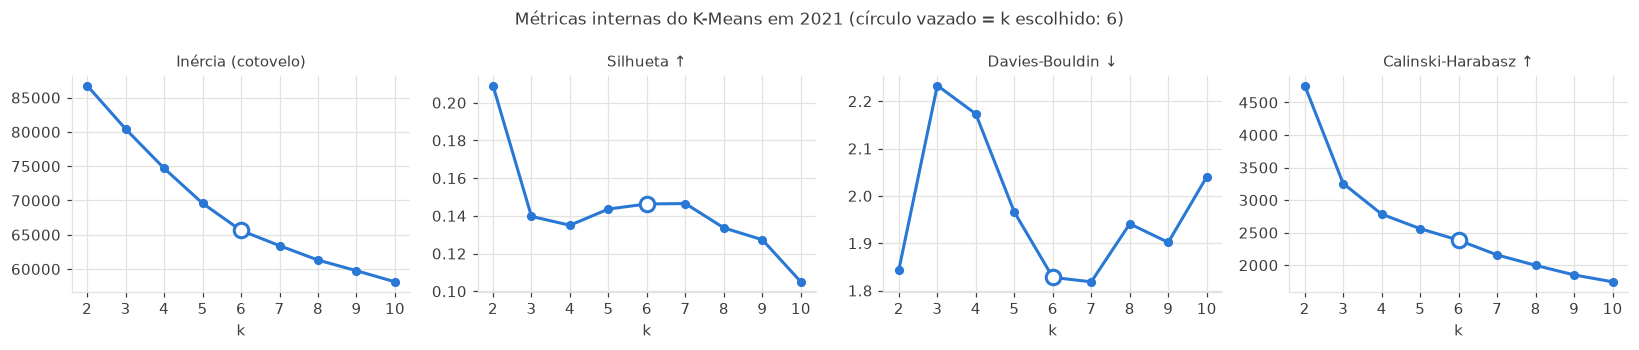

In [3]:
por_k = pd.DataFrame(metricas["metricas_por_k"])
display(por_k)

fig, eixos = plt.subplots(1, 4, figsize=(15, 3.2))
for eixo, (coluna, titulo) in zip(eixos, [
    ("inercia", "Inércia (cotovelo)"),
    ("silhueta", "Silhueta ↑"),
    ("davies_bouldin", "Davies-Bouldin ↓"),
    ("calinski_harabasz", "Calinski-Harabasz ↑"),
]):
    eixo.plot(por_k["k"], por_k[coluna], color=AZUL, linewidth=2, marker="o", markersize=5)
    escolhido = por_k.loc[por_k["k"] == metricas["k_escolhido"], coluna].iloc[0]
    eixo.scatter([metricas["k_escolhido"]], [escolhido], s=90, facecolor="white", edgecolor=AZUL, linewidth=2, zorder=3)
    eixo.set_title(titulo, fontsize=10)
    eixo.set_xlabel("k")
    eixo.set_xticks(por_k["k"])
fig.suptitle(f"Métricas internas do K-Means em {ANO} (círculo vazado = k escolhido: {metricas['k_escolhido']})", fontsize=11, color=CINZA_TEXTO)
fig.tight_layout()
plt.show()

**Leitura:** como no agrupamento conjunto, a silhueta é baixa em todos os valores de k: as escolas formam um contínuo, e os grupos são uma tipologia para definir pares, não tipos naturais. Em 2021, k = 6 e k = 7 empatam na silhueta (0,146), e o Davies-Bouldin é praticamente igual nos dois (1,83 e 1,82). O k = 6 foi mantido para que os anos sejam comparáveis.

## 3. Estabilidade e comparação com outros algoritmos

In [4]:
estab = metricas["estabilidade"]
print("ARI entre sementes:      ", estab["ari_entre_sementes"])
print("ARI entre reamostragens: ", estab["ari_entre_reamostragens"])
print("ARI StandardScaler × RobustScaler:", metricas["ari_standard_vs_robust"])
print("Ward (amostra):    ", metricas["comparacao_algoritmos"]["ward"])
print("HDBSCAN (amostra): ", metricas["comparacao_algoritmos"]["hdbscan"])

ARI entre sementes:       [0.9993, 0.9947, 1.0]
ARI entre reamostragens:  [0.9759, 0.9867, 0.9474]
ARI StandardScaler × RobustScaler: 0.1659
Ward (amostra):     {'silhueta': 0.0795, 'ari_com_kmeans': 0.29}
HDBSCAN (amostra):  {'min_cluster_size': 100, 'grupos': 2, 'fracao_ruido': 0.0115}


**Leitura:** A partição é estável entre sementes (ARI ≥ 0,995), e um pouco menos entre reamostragens (ARI de 0,95 a 0,99), por ser o ano com menos escolas. A sensibilidade ao `RobustScaler` é a maior dos três anos (ARI 0,17). O HDBSCAN encontra só duas regiões densas, separadas pela presença de psicólogo, como no agrupamento conjunto.

## 4. Comparação com o agrupamento conjunto (três anos juntos)

Se o agrupamento feito só com este ano reproduzir o agrupamento conjunto, a tabela cruzada abaixo fica concentrada na diagonal. Isso indica que os perfis não dependem de juntar os anos.

In [5]:
comparacao = atribuicoes.merge(conjunto, on=["id_escola", "ano"], suffixes=("_ano", "_conjunto"), validate="one_to_one")
ari = adjusted_rand_score(comparacao["cluster_ano"], comparacao["cluster_conjunto"])
print(f"ARI entre o agrupamento de {ANO} e o agrupamento conjunto: {ari:.3f}")
print(f"Escolas no mesmo grupo nas duas versões: {100 * (comparacao['cluster_ano'] == comparacao['cluster_conjunto']).mean():.1f}%")
pd.crosstab(comparacao["cluster_ano"], comparacao["cluster_conjunto"], rownames=[f"grupo em {ANO}"], colnames=["grupo no conjunto"])

ARI entre o agrupamento de 2021 e o agrupamento conjunto: 0.941
Escolas no mesmo grupo nas duas versões: 97.1%


grupo no conjunto,0,1,2,3,4,5
grupo em 2021,,,,,,
0,5677,3,24,0,0,0
1,124,2606,27,0,31,3
2,0,8,2569,0,0,29
3,0,8,15,787,15,62
4,14,5,0,0,3029,1
5,0,22,5,0,106,2302


## 5. Perfil dos grupos

In [6]:
NOMES = {
    0: "Recursos mínimos",
    1: "Espaços sem tecnologia",
    2: "Materiais sem tecnologia",
    3: "Apoio multiprofissional",
    4: "Tecnologia sem espaços",
    5: "Estrutura completa",
}
ROTULOS = [f"{c} · {NOMES[c]}" for c in perfis.index]

resumo = pd.DataFrame({
    "grupo": [NOMES[c] for c in perfis.index],
    "escolas": perfis["escolas_ano"],
    "% do total": 100 * perfis["escolas_ano"] / perfis["escolas_ano"].sum(),
    "matrícula mediana": perfis["matricula_mediana"],
    "% rural": 100 * perfis["prop_localizacao_rural"],
    "% estadual": 100 * perfis["prop_rede_estadual"],
    "% oferece médio": 100 * perfis["media_oferece_medio"],
})
display(resumo)

,grupo,escolas,% do total,matrícula mediana,% rural,% estadual,% oferece médio
cluster,,,,,,,
0,Recursos mínimos,5704,32.65,185.50,63.32,4.73,2.89
1,Espaços sem tecnologia,2791,15.97,379.00,27.91,14.44,8.99
2,Materiais sem tecnologia,2606,14.92,299.00,39.56,7.64,2.95
3,Apoio multiprofissional,887,5.08,281.00,37.32,2.59,1.47
4,Tecnologia sem espaços,3049,17.45,272.00,34.77,21.55,11.81
5,Estrutura completa,2435,13.94,483.00,9.82,64.89,57.29


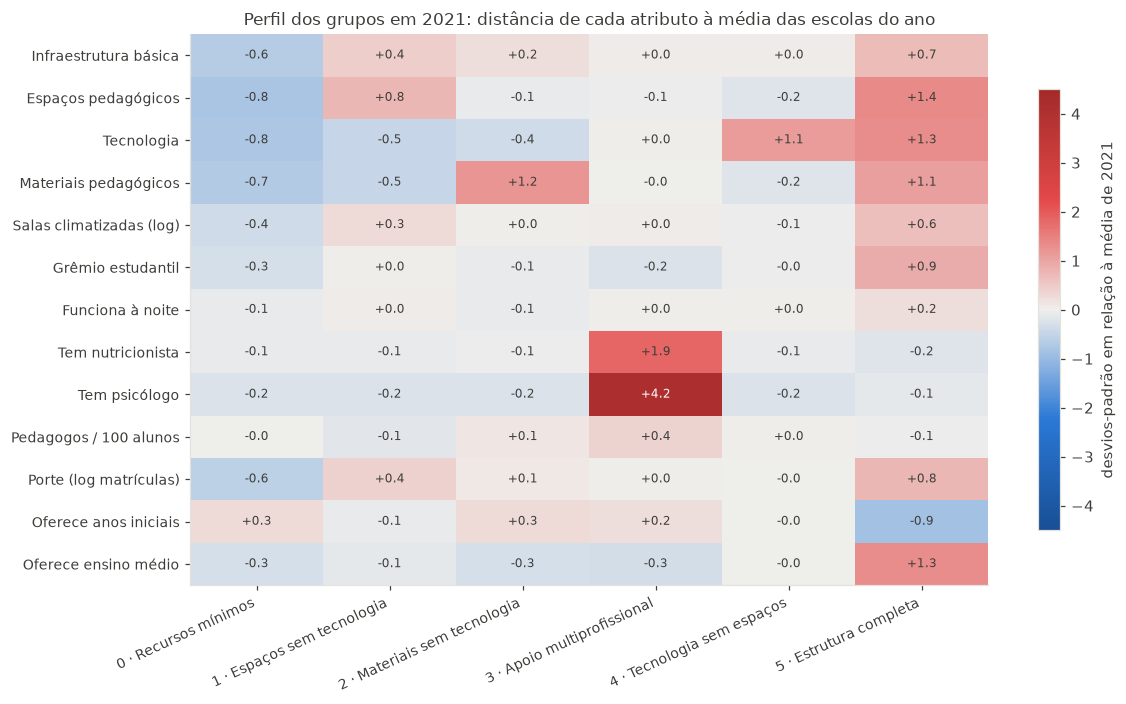

In [7]:
destaques = {
    "media_indice_infraestrutura_basica": "Infraestrutura básica",
    "media_indice_espacos_pedagogicos": "Espaços pedagógicos",
    "media_indice_tecnologia": "Tecnologia",
    "media_indice_materiais": "Materiais pedagógicos",
    "media_salas_climatizadas_log": "Salas climatizadas (log)",
    "media_orgao_gremio_estudantil": "Grêmio estudantil",
    "media_noturno": "Funciona à noite",
    "media_tem_nutricionista": "Tem nutricionista",
    "media_tem_psicologo": "Tem psicólogo",
    "media_profissional_pedagogia_100_alunos": "Pedagogos / 100 alunos",
    "media_porte_log": "Porte (log matrículas)",
    "media_oferece_iniciais": "Oferece anos iniciais",
    "media_oferece_medio": "Oferece ensino médio",
}
# Média e desvio-padrão das escolas deste ano, para que a régua seja a do próprio ano.
geral = matriz[[c.removeprefix("media_") for c in destaques]].agg(["mean", "std"])
z = pd.DataFrame({
    rotulo: (perfis[coluna] - geral.loc["mean", coluna.removeprefix("media_")]) / geral.loc["std", coluna.removeprefix("media_")]
    for coluna, rotulo in destaques.items()
}).T
z.columns = ROTULOS

divergente = LinearSegmentedColormap.from_list("divergente", ["#184f95", "#2a78d6", "#f0efec", "#e34948", "#a32a2a"])
# Escala fixa nos três anos, para que as cores sejam comparáveis entre os notebooks.
limite = 4.5

fig, eixo = plt.subplots(figsize=(11, 6.5))
imagem = eixo.imshow(z.clip(-limite, limite), cmap=divergente, vmin=-limite, vmax=limite, aspect="auto")
eixo.set_xticks(range(len(z.columns)), z.columns, rotation=25, ha="right", fontsize=9)
eixo.set_yticks(range(len(z.index)), z.index, fontsize=9)
eixo.grid(False)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        valor = z.iat[i, j]
        eixo.text(j, i, f"{valor:+.1f}", ha="center", va="center", fontsize=8,
                  color="white" if abs(valor) > 0.6 * limite else CINZA_TEXTO)
barra = fig.colorbar(imagem, ax=eixo, shrink=0.8)
barra.set_label(f"desvios-padrão em relação à média de {ANO}")
eixo.set_title(f"Perfil dos grupos em {ANO}: distância de cada atributo à média das escolas do ano", fontsize=11)
fig.tight_layout()
plt.show()

Os nomes são os mesmos do agrupamento conjunto. Eles só valem para este ano porque a comparação da seção 4 mostra que cada grupo corresponde ao mesmo grupo do conjunto, e o mapa de calor acima confirma os mesmos destaques.

## 6. IDEB por grupo e etapa

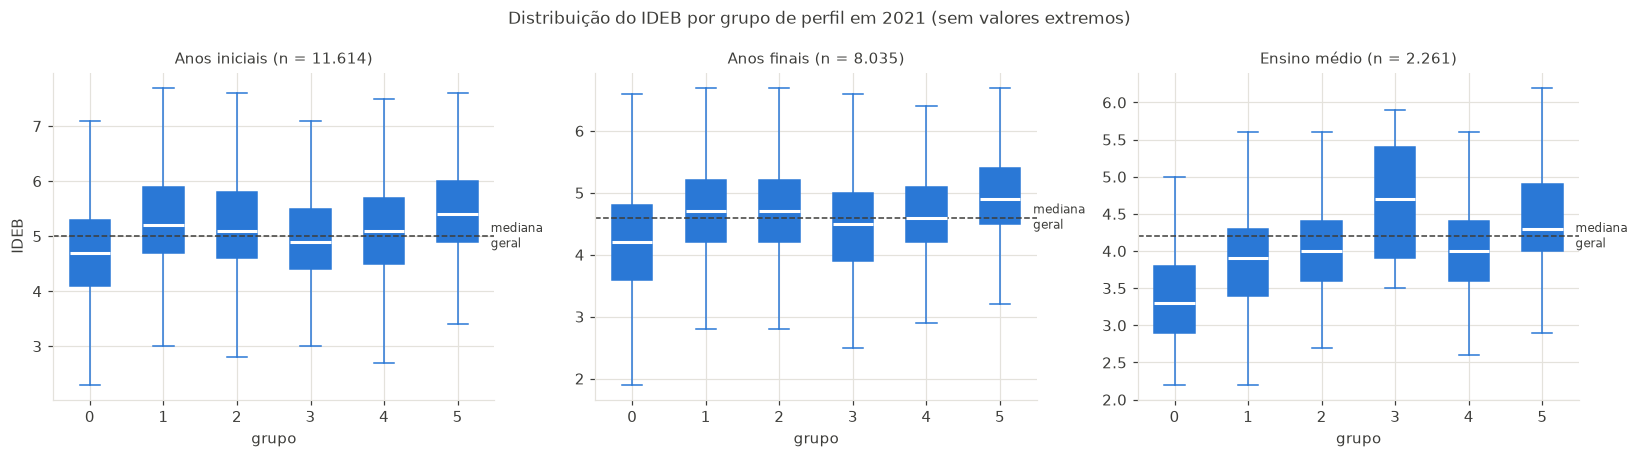

anos_escolares,Anos finais,Anos iniciais,Ensino médio
0 · Recursos mínimos,4.2 (n = 2136),4.7 (n = 4519),3.3 (n = 165)
1 · Espaços sem tecnologia,4.7 (n = 1689),5.2 (n = 1736),3.9 (n = 251)
2 · Materiais sem tecnologia,4.7 (n = 1247),5.1 (n = 2060),4.0 (n = 77)
3 · Apoio multiprofissional,4.5 (n = 437),4.9 (n = 679),4.7 (n = 13)
4 · Tecnologia sem espaços,4.6 (n = 1560),5.1 (n = 2002),4.0 (n = 360)
5 · Estrutura completa,4.9 (n = 966),5.4 (n = 618),4.3 (n = 1395)


In [8]:
ideb = ligacao.merge(atribuicoes, on=["id_escola", "ano"], validate="many_to_one")
ETAPAS = {"iniciais (1-5)": "Anos iniciais", "finais (6-9)": "Anos finais", "todos (1-4)": "Ensino médio"}

fig, eixos = plt.subplots(1, 3, figsize=(15, 4.2))
for eixo, (etapa, titulo) in zip(eixos, ETAPAS.items()):
    dados = ideb[ideb["anos_escolares"] == etapa]
    grupos = [dados.loc[dados["cluster"] == c, "ideb"].dropna() for c in perfis.index]
    eixo.boxplot(
        grupos, tick_labels=[str(c) for c in perfis.index], widths=0.55, patch_artist=True,
        showfliers=False, medianprops={"color": "white", "linewidth": 2},
        boxprops={"facecolor": AZUL, "edgecolor": AZUL},
        whiskerprops={"color": AZUL}, capprops={"color": AZUL},
    )
    geral_etapa = dados["ideb"].median()
    eixo.axhline(geral_etapa, color=CINZA_TEXTO, linewidth=1, linestyle="--")
    eixo.text(len(grupos) + 0.45, geral_etapa, "mediana\ngeral", fontsize=8, va="center", color=CINZA_TEXTO)
    eixo.set_title(f"{titulo} (n = {len(dados):,})".replace(",", "."), fontsize=10)
    eixo.set_xlabel("grupo")
eixos[0].set_ylabel("IDEB")
fig.suptitle(f"Distribuição do IDEB por grupo de perfil em {ANO} (sem valores extremos)", fontsize=11, color=CINZA_TEXTO)
fig.tight_layout()
plt.show()

contagem = ideb.groupby(["cluster", "anos_escolares"])["ideb"].count().unstack().rename(columns=ETAPAS)
mediana = ideb.groupby(["cluster", "anos_escolares"])["ideb"].median().unstack().rename(columns=ETAPAS)
tabela = mediana.round(2).astype(str) + " (n = " + contagem.astype(int).astype(str) + ")"
tabela.index = ROTULOS
tabela

**Leitura:** O IDEB de 2021 deve ser lido com cautela: a taxa de aprovação mediana chegou a 100% nos anos iniciais e a 99% nos finais, o que eleva o indicador de rendimento e, com ele, o IDEB, sem melhora correspondente no Saeb. A ordem entre os grupos se mantém (0 menor, 5 maior). O grupo 3 tem só 13 observações no ensino médio, então essa célula não deve ser interpretada. Associação não é causa: os grupos também diferem em rede, localização e porte.

## 7. Composição dos grupos e escolas imputadas

In [9]:
composicao = perfis[["prop_rede_municipal", "prop_rede_estadual", "prop_localizacao_rural", "prop_materiais_imputados", "prop_gremio_imputado"]].mul(100)
composicao.index = ROTULOS
composicao.columns = ["% municipal", "% estadual", "% rural", "% materiais imputados", "% grêmio imputado"]
composicao

,% municipal,% estadual,% rural,% materiais imputados,% grêmio imputado
0 · Recursos mínimos,95.27,4.73,63.32,0.00,0.00
1 · Espaços sem tecnologia,85.56,14.44,27.91,0.00,0.00
2 · Materiais sem tecnologia,92.36,7.64,39.56,0.00,0.00
3 · Apoio multiprofissional,97.18,2.59,37.32,0.00,0.00
4 · Tecnologia sem espaços,78.39,21.55,34.77,0.00,0.00
5 · Estrutura completa,34.46,64.89,9.82,0.00,0.00


Em 2021 não há imputação de materiais nem de grêmio: esses ausentes só ocorrem em 2019.